# Top-view image

In [893]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import itertools
import numpy as np
import math

In [894]:
DATA_DIR = Path("./../data")
# IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"
IMAGE_PATH = DATA_DIR / "development_set/4a_png.rf.a6bb5c5706fd8628eb53d34a122cf441.jpg"

In [895]:
image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply Gaussian
image = cv2.GaussianBlur(image, (15, 15), 0)

# Mask Blue cloth
hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

lower_blue = np.array([200/2, 60 / 100 * 255, 60 / 100 * 255])
upper_blue = np.array([210/2, 110 / 100 * 255, 110 / 100 * 255])

mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

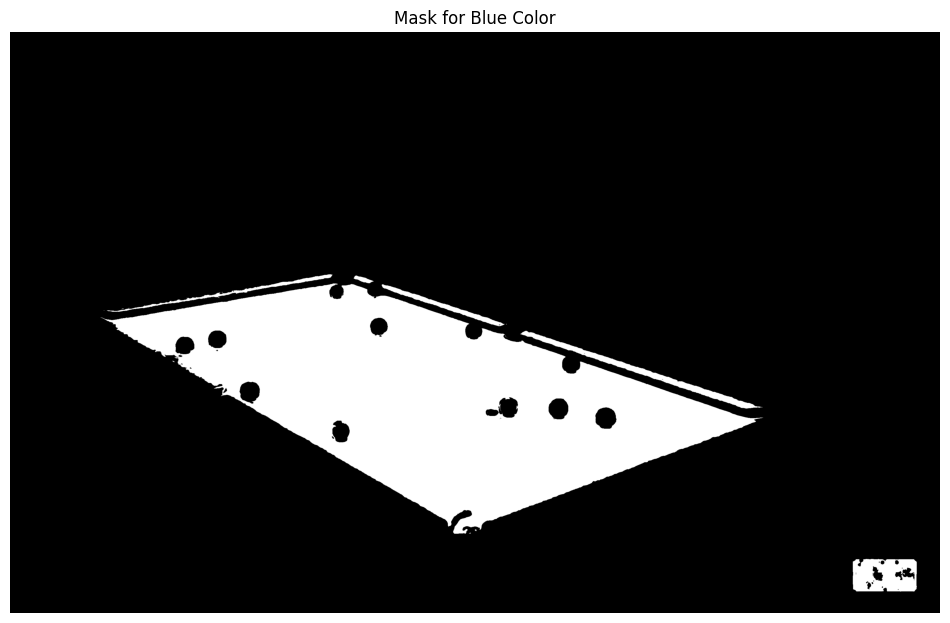

In [896]:
plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title('Mask for Blue Color')
plt.show()

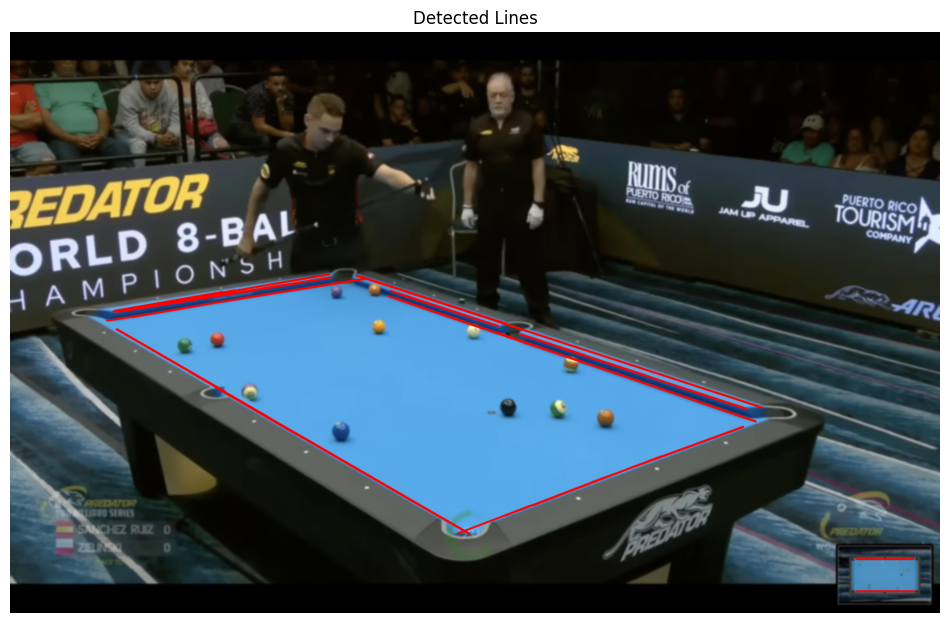

In [897]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

line_image = image.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(line_image, (x1, y1), (x2, y2), (255, 0, 0), 5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Detected Lines')
plt.show()

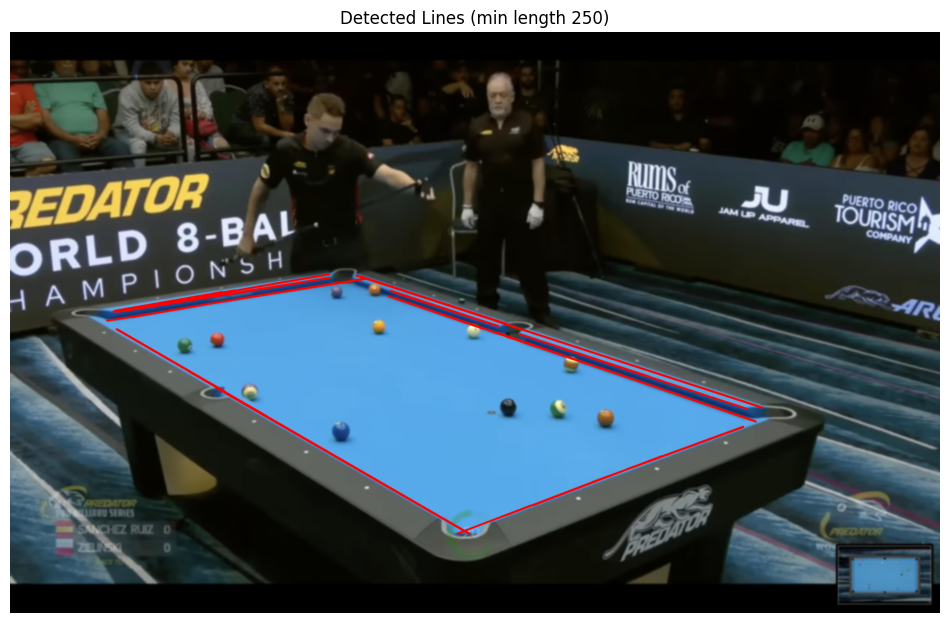

In [898]:
# drop lines shorter than 150 pixels
tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

line_image = image.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(line_image, (x1, y1), (x2, y2), (255, 0, 0), 5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Detected Lines (min length 250)')
plt.show()

In [899]:
mid_points = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    mid_points.append(((x1 + x2) // 2, (y1 + y2) // 2))

center = np.mean(mid_points, axis=0).astype(int)
print("Center of the table:", center)

Center of the table: [1478 1172]


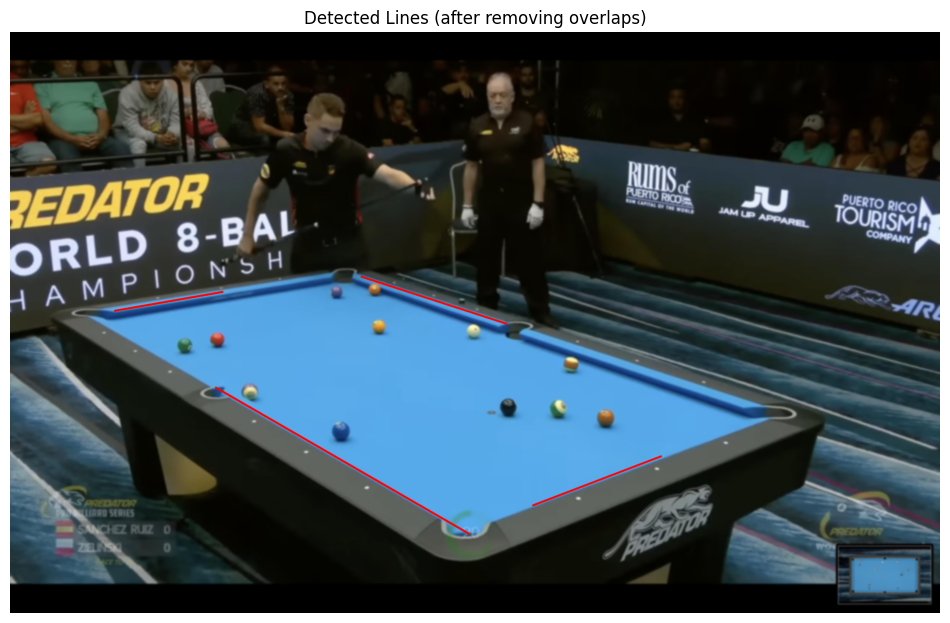

In [900]:
def get_hessel(line):
    x1, y1, x2, y2 = line[0]
    
    dx, dy = x2 - x1, y2 - y1

    length = math.sqrt(dx ** 2 + dy ** 2)
    if length < 1e-6:
        return None

    theta = math.atan2(dy, dx) + np.pi / 2
    theta = theta % np.pi

    rho = x1 * math.cos(theta) + y1 * math.sin(theta)

    return (rho, theta)

def get_diff_pi(a, b):
    diff = abs(a - b)
    return min(diff, np.pi - diff)

def get_dist_center(rho, theta, center):
    cx, cy = center
    return cx * math.cos(theta) + cy * math.sin(theta) - rho

segments = []
for line in lines:
    rho, theta = get_hessel(line)
    segments.append((
        line,
        rho,
        theta
    ))

over_line = []
all_lines = {}

for i in range(len(segments)):
    all_lines[i] = segments[i]
    for j in range(i + 1, len(segments)):
        rho1, theta1 = segments[i][1], segments[i][2]
        rho2, theta2 = segments[j][1], segments[j][2]

        if get_diff_pi(theta1, theta2) > 0.05:
            continue
        
        # print(abs(rho1 - rho2))
        if abs(rho1 - rho2) > 50:
            continue
        
        # print(f"rho={rho1:.2f}, theta={theta1:.2f}; rho={rho2:.2f}, theta={theta2:.2f}; difference: {get_diff_pi(theta1, theta2):.2f} rad")

        dist1 = get_dist_center(rho1, theta1, center)
        dist2 = get_dist_center(rho2, theta2, center)

        # print(f"Distance to center: {dist1:.2f}, {dist2:.2f}")

        if abs(dist1) > abs(dist2):
            over_line.append((i, j))
            # print(f"Line {i} is over line {j}")
        else:
            over_line.append((j, i))
            # print(f"Line {j} is over line {i}")

to_remove = set()
for segment_id, v in all_lines.items():
    for i, j in over_line:
        if segment_id == j:
            to_remove.add(j)

for segment_id in to_remove:
    all_lines.pop(segment_id, None)

line_image = image.copy()
for segment_id, (line, rho, theta) in all_lines.items():
    x1, y1, x2, y2 = line[0]
    cv2.line(line_image, (x1, y1), (x2, y2), (255, 0, 0), 5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Detected Lines (after removing overlaps)')
plt.show()

[[1643.1204  1804.9972 ]
 [ 289.38376 1024.451  ]
 [2773.0662  1373.0309 ]
 [1204.0544   864.97   ]]


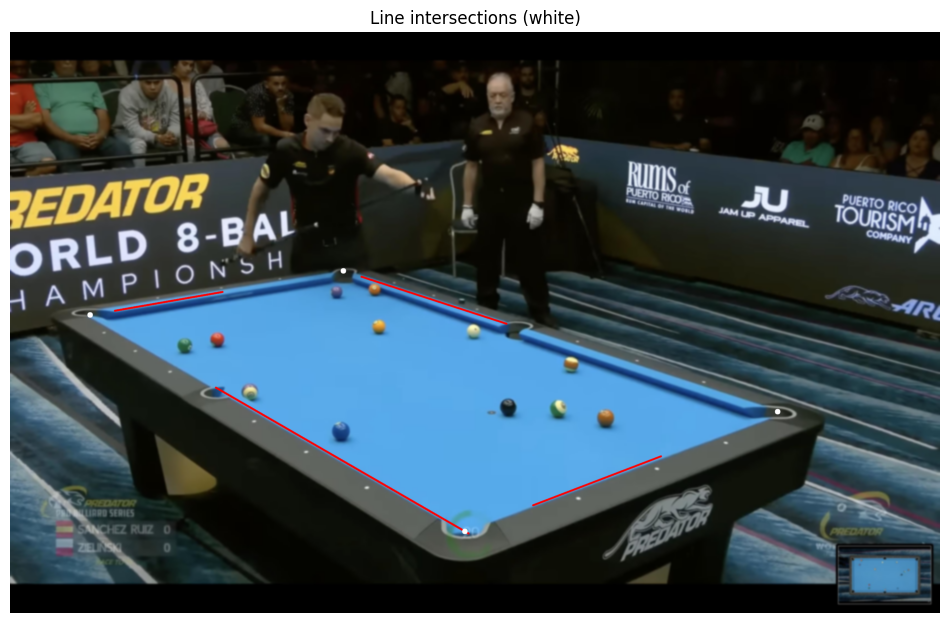

In [901]:
def line_intersection_infinite(l1, l2, eps=1e-9):
    x1, y1, x2, y2 = l1[0]
    x3, y3, x4, y4 = l2[0]

    denom = (x1 - x2) * (y3 - y4) - (y1 - y2) * (x3 - x4)
    if abs(denom) < eps:
        return None

    det1 = x1 * y2 - y1 * x2
    det2 = x3 * y4 - y3 * x4
    px = (det1 * (x3 - x4) - (x1 - x2) * det2) / denom
    py = (det1 * (y3 - y4) - (y1 - y2) * det2) / denom
    return float(px), float(py)

line_segments = [seg[0] for seg in all_lines.values()]  # each is shape (1, 4)
h, w = image.shape[:2]

raw_points = []
for l1, l2 in itertools.combinations(line_segments, 2):
    p = line_intersection_infinite(l1, l2)
    if p is None:
        continue
    x, y = p

    if -100 <= x <= (w - 1) + 100 and -100 <= y <= (h - 1) + 100:
        raw_points.append((x, y))

intersection_points = np.array(list(raw_points), dtype=np.float32)

print(intersection_points)

intersection_image = image.copy()
for seg in line_segments:
    x1, y1, x2, y2 = seg[0]
    cv2.line(intersection_image, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 5)

for x, y in intersection_points:
    cv2.circle(intersection_image, (int(round(x)), int(round(y))), 10, (255, 255, 255), -1)

plt.figure(figsize=(12, 8))
plt.imshow(intersection_image)
plt.axis('off')
plt.title('Line intersections (white)')
plt.show()

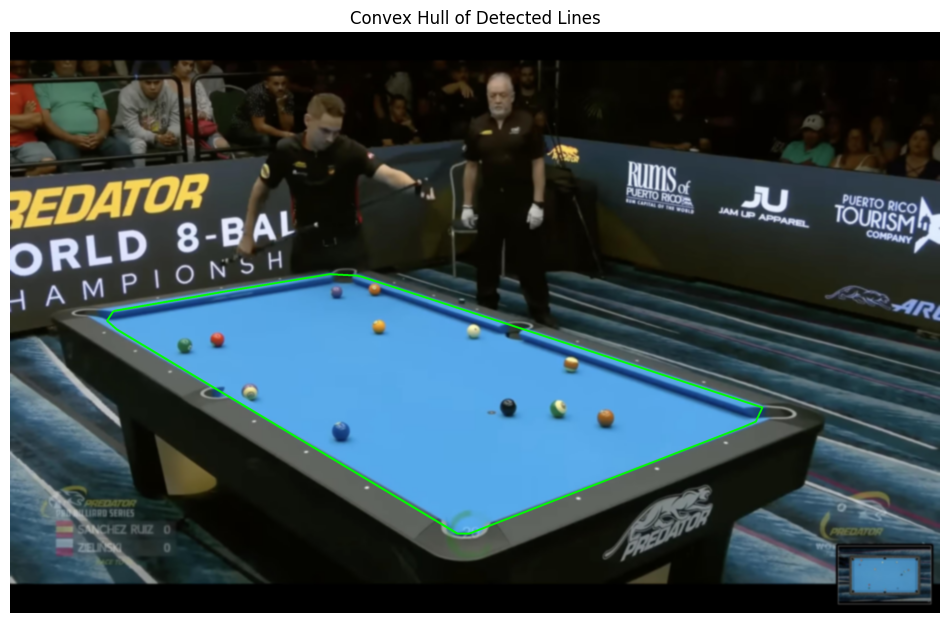

In [902]:
pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

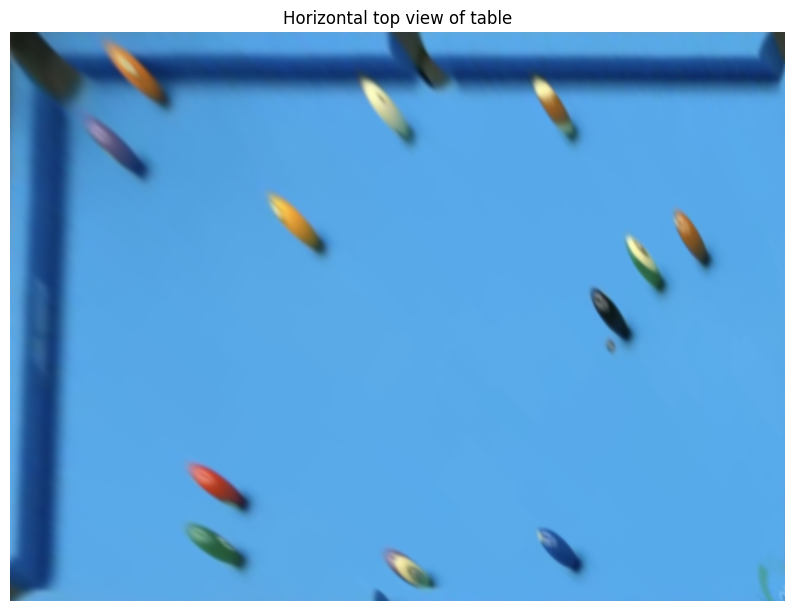

In [903]:
# TODO: do it better
tl = intersection_points[2]
tr = intersection_points[0]
br = intersection_points[1]
bl = intersection_points[3]

rect = np.array([tl, tr, br, bl], dtype=np.float32)

width_top = np.linalg.norm(tr - tl)
width_bottom = np.linalg.norm(br - bl)
max_width = int(round(max(width_top, width_bottom)))

height_left = np.linalg.norm(bl - tl)
height_right = np.linalg.norm(br - tr)
max_height = int(round(max(height_left, height_right)))

dst = np.array([
    [0, 0],
    [max_width - 1, 0],
    [max_width - 1, max_height - 1],
    [0, max_height - 1]
], dtype=np.float32)

M = cv2.getPerspectiveTransform(rect, dst)
warped = cv2.warpPerspective(image, M, (max_width, max_height))

# Force horizontal output
if warped.shape[0] > warped.shape[1]:  # height > width
    warped = cv2.rotate(warped, cv2.ROTATE_90_CLOCKWISE)

plt.figure(figsize=(10, 8))
plt.imshow(warped)
plt.axis("off")
plt.title("Horizontal top view of table")
plt.show()